# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Faiz Farrosian Karim | 5054251027 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_style('whitegrid')
RANDOM_STATE = 42

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('data.csv')

print("Jumlah baris dan kolom:", df.shape)
print()
df.info()

Jumlah baris dan kolom: (569, 33)

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  pe

In [3]:
# 5 baris pertama dan statistik deskriptif
display(df.head())
display(df.describe().T)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [4]:
# Jumlah missing value per kolom (hanya yang ada isinya)
missing = df.isnull().sum()
print(missing[missing > 0])

Unnamed: 32    569
dtype: int64


diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64


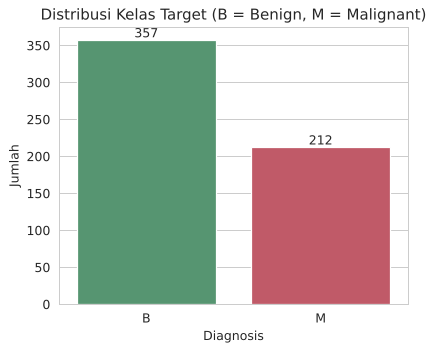

In [5]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
counts = df['diagnosis'].value_counts()
persen = df['diagnosis'].value_counts(normalize=True) * 100
print(counts)
print(persen.round(2))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x='diagnosis', data=df, order=['B', 'M'], palette=['#4C9F70', '#D1495B'])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Distribusi Kelas Target (B = Benign, M = Malignant)')
plt.xlabel('Diagnosis')
plt.ylabel('Jumlah')
plt.show()

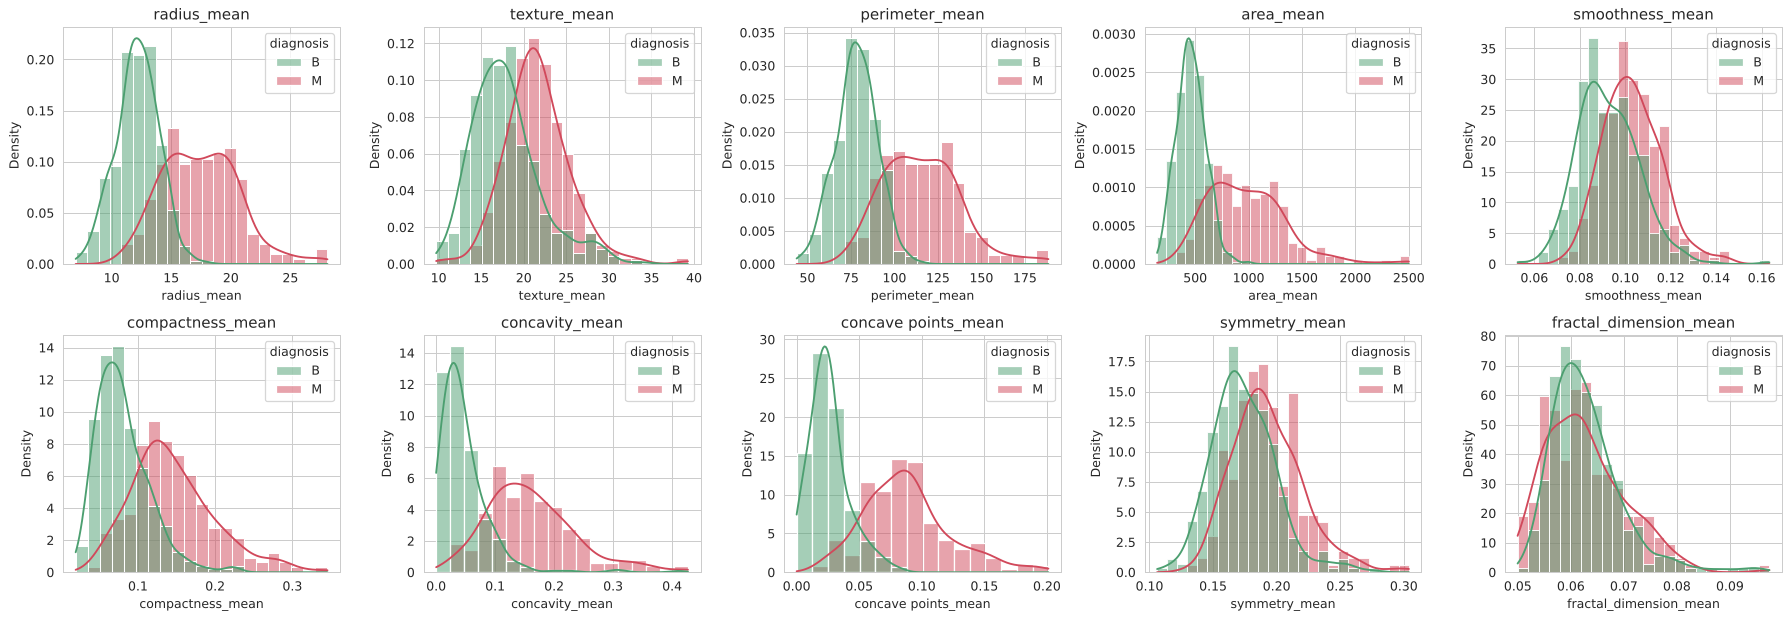

In [6]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas (linear) antar kelas, atau justru tumpang tindih.
fitur_mean = [c for c in df.columns if c.endswith('_mean')]

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), fitur_mean):
    sns.histplot(data=df, x=col, hue='diagnosis', hue_order=['B', 'M'],
                 palette=['#4C9F70', '#D1495B'], kde=True, ax=ax, stat='density', common_norm=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

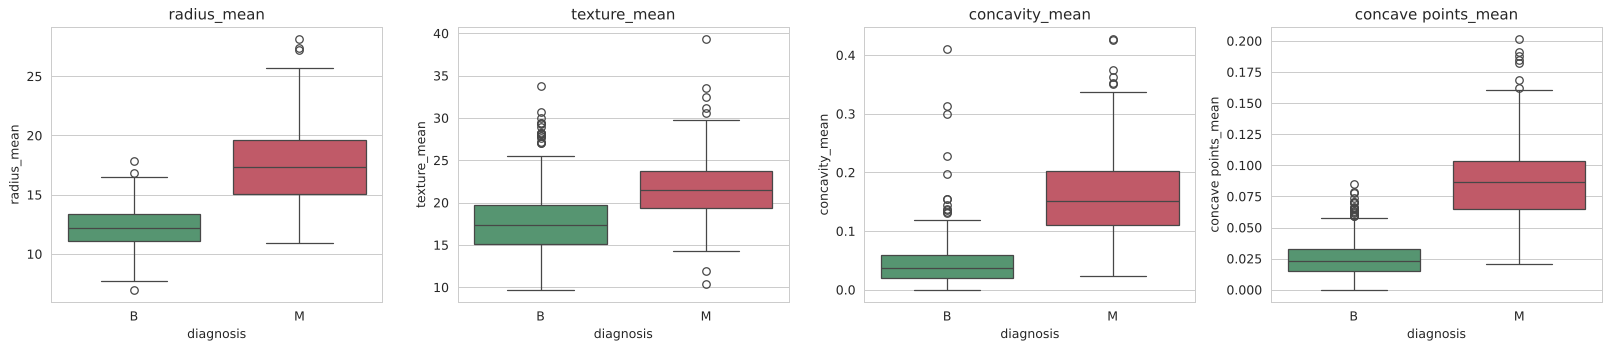

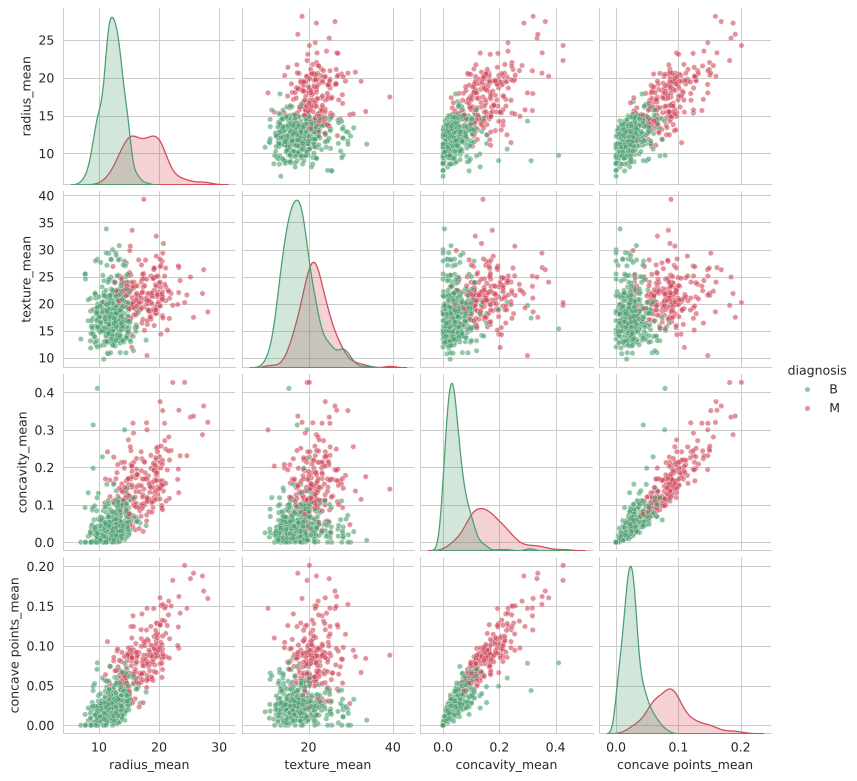

In [7]:
# Boxplot beberapa fitur utama per kelas
fitur_pilihan = ['radius_mean', 'texture_mean', 'concavity_mean', 'concave points_mean']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, fitur_pilihan):
    sns.boxplot(data=df, x='diagnosis', y=col, order=['B', 'M'],
                palette=['#4C9F70', '#D1495B'], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Pairplot 4 fitur (sampel kelas B dan M)
sns.pairplot(df[fitur_pilihan + ['diagnosis']], hue='diagnosis', hue_order=['B', 'M'],
             palette=['#4C9F70', '#D1495B'], height=2.2, plot_kws={'alpha': 0.6, 's': 18})
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

10 fitur dengan korelasi tertinggi terhadap target:
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
Name: target, dtype: float64


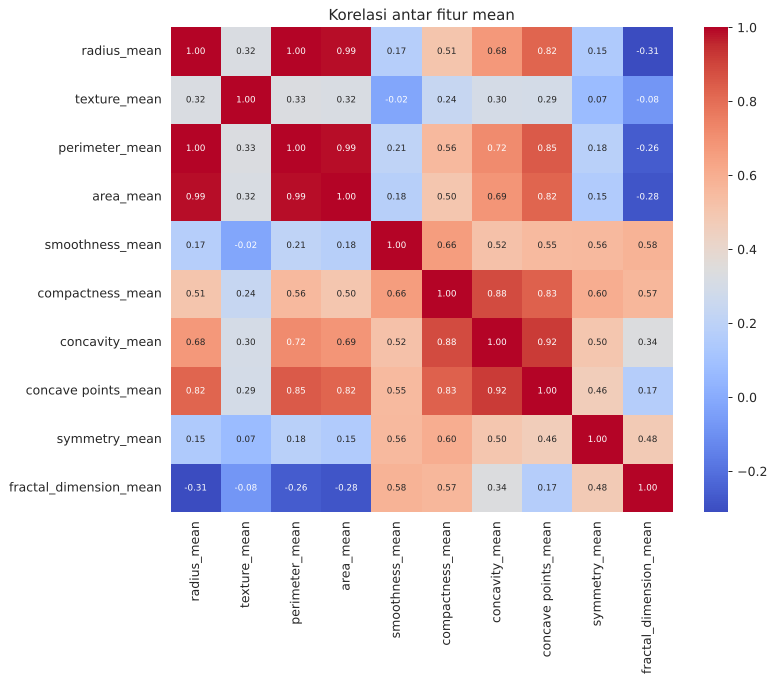

In [8]:
# EDA tambahan 1: korelasi antar fitur mean dan korelasi fitur dengan target
df_eda = df.drop(columns=['id', 'Unnamed: 32']).copy()
df_eda['target'] = df_eda['diagnosis'].map({'B': 0, 'M': 1})

plt.figure(figsize=(9, 7))
sns.heatmap(df_eda[fitur_mean].corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Korelasi antar fitur mean')
plt.show()

print("10 fitur dengan korelasi tertinggi terhadap target:")
print(df_eda.drop(columns='diagnosis').corr()['target'].drop('target')
      .abs().sort_values(ascending=False).head(10).round(3))

In [9]:
# EDA tambahan 2: rentang nilai fitur (untuk melihat perlu tidaknya scaling)
rentang = df_eda.drop(columns=['diagnosis', 'target']).agg(['min', 'max']).T
rentang['range'] = rentang['max'] - rentang['min']
print(rentang.sort_values('range', ascending=False).head(5).round(3))
print("...")
print(rentang.sort_values('range').head(5).round(5))

                     min     max     range
area_worst       185.200  4254.0  4068.800
area_mean        143.500  2501.0  2357.500
area_se            6.802   542.2   535.398
perimeter_worst   50.410   251.2   200.790
perimeter_mean    43.790   188.5   144.710
...
                            min      max    range
fractal_dimension_se    0.00089  0.02984  0.02895
smoothness_se           0.00171  0.03113  0.02942
fractal_dimension_mean  0.04996  0.09744  0.04748
concave points_se       0.00000  0.05279  0.05279
symmetry_se             0.00788  0.07895  0.07107


**Ringkasan EDA**

- Dataset berisi 569 baris dan 30 fitur numerik (hasil pengukuran inti sel: `mean`, `se`, `worst` dari 10 karakteristik), dengan target `diagnosis` (B = Benign, M = Malignant).
- Ada kolom `Unnamed: 32` yang isinya kosong semua (569 missing) dan kolom `id`. Keduanya tidak berguna sebagai fitur sehingga dibuang di tahap preprocessing. Fitur lainnya tidak ada yang missing.
- Kelas sedikit **imbalanced**: Benign 357 (62.7%) dan Malignant 212 (37.3%). Tidak terlalu parah, tapi akurasi saja kurang cukup, jadi nanti precision, recall, dan F1 untuk kelas Malignant juga dilihat.
- Dari histogram, boxplot, dan pairplot, fitur ukuran (`radius`, `perimeter`, `area`) dan bentuk (`concavity`, `concave points`) membedakan kedua kelas dengan cukup jelas. Kelas Malignant cenderung bernilai lebih besar. Namun masih ada daerah tumpang tindih di bagian tengah, terutama pada `texture_mean` dan `smoothness_mean`.
- Pada pasangan fitur seperti `radius_mean` vs `concave points_mean`, kedua kelas terlihat bisa dipisah dengan garis lurus hampir sempurna, kecuali sedikit titik di perbatasan. Ini mengindikasikan data **cukup linear separable**.
- Banyak fitur berkorelasi sangat tinggi (misal `radius`, `perimeter`, `area`), jadi informasinya redundan. Fitur dengan korelasi tertinggi ke target adalah `concave points_worst` (0.79), `perimeter_worst` (0.78), dan `concave points_mean` (0.78).
- Rentang nilai antar fitur sangat timpang: `area_worst` rentangnya sekitar 4069, sedangkan `fractal_dimension_se` hanya sekitar 0.03. Karena SVM berbasis jarak, kondisi ini membuat feature scaling wajib dilakukan.

# 2. Preprocessing

In [10]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

# Kolom 'Unnamed: 32' isinya NaN semua (569 dari 569 baris), jadi tidak ada informasi sama sekali -> dibuang.
# Kolom 'id' hanya identitas pasien, bukan fitur -> dibuang juga supaya tidak jadi noise.
# Karena yang dibuang adalah satu kolom utuh (bukan imputasi dengan statistik data),
# tidak ada risiko data leakage.
df_clean = df.drop(columns=['id', 'Unnamed: 32'])

print("Sisa missing value:", df_clean.isnull().sum().sum())
print("Bentuk data sekarang:", df_clean.shape)

Sisa missing value: 0
Bentuk data sekarang: (569, 31)


In [11]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
# Semua fitur sudah numerik. Satu-satunya kolom kategorikal adalah target 'diagnosis',
# jadi cukup di-encode jadi biner: B (Benign) = 0, M (Malignant) = 1.
df_clean['diagnosis'] = df_clean['diagnosis'].map({'B': 0, 'M': 1})
print(df_clean['diagnosis'].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [12]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.
X = df_clean.drop(columns='diagnosis')
y = df_clean['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Ukuran X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi kelas malignant -> train: %.3f | test: %.3f | asli: %.3f"
      % (y_train.mean(), y_test.mean(), y.mean()))

Ukuran X_train: (455, 30) | X_test: (114, 30)
Proporsi kelas malignant -> train: 0.374 | test: 0.368 | asli: 0.373


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [13]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Cek: rata-rata ~0 dan std ~1 pada train set
print("Mean train (5 fitur pertama):", X_train_scaled.mean(axis=0)[:5].round(3))
print("Std  train (5 fitur pertama):", X_train_scaled.std(axis=0)[:5].round(3))

Mean train (5 fitur pertama): [-0.  0.  0. -0.  0.]
Std  train (5 fitur pertama): [1. 1. 1. 1. 1.]


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [14]:
# Inisialisasi dan latih model SVC dengan kernel='linear' menggunakan train set (yang sudah discaling).
svm_linear = SVC(kernel='linear', C=1.0, random_state=RANDOM_STATE)
svm_linear.fit(X_train_scaled, y_train)

print("Akurasi train (Linear):", round(svm_linear.score(X_train_scaled, y_train), 4))

Akurasi train (Linear): 0.989


In [15]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_linear = svm_linear.predict(X_test_scaled)
print("Akurasi test (Linear):", round(accuracy_score(y_test, y_pred_linear), 4))

Akurasi test (Linear): 0.9649


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [16]:
# Inisialisasi dan latih model SVC dengan kernel='rbf' menggunakan train set.
# Gunakan nilai hyperparameter lain (C) yang sama seperti model Linear di atas, agar perbandingan adil.
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=RANDOM_STATE)
svm_rbf.fit(X_train_scaled, y_train)

print("Akurasi train (RBF):", round(svm_rbf.score(X_train_scaled, y_train), 4))
print("Nilai gamma='scale' yang dipakai:", round(svm_rbf._gamma, 5))

Akurasi train (RBF): 0.9868
Nilai gamma='scale' yang dipakai: 0.03333


In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
y_pred_rbf = svm_rbf.predict(X_test_scaled)
print("Akurasi test (RBF):", round(accuracy_score(y_test, y_pred_rbf), 4))

Akurasi test (RBF): 0.9737


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [18]:
# Latih beberapa model SVC (kernel RBF) dengan variasi nilai C,
# misalnya 0.01, 0.1, 1, 10, 100.
# Gunakan gamma='scale' atau nilai gamma tetap agar perbandingan fokus pada pengaruh C.
nilai_C = [0.01, 0.1, 1, 10, 100, 1000]
model_per_C = {}
for c in nilai_C:
    m = SVC(kernel='rbf', C=c, gamma='scale', random_state=RANDOM_STATE)
    m.fit(X_train_scaled, y_train)
    model_per_C[c] = m
print("Model terlatih untuk C =", nilai_C)

Model terlatih untuk C = [0.01, 0.1, 1, 10, 100, 1000]


In [19]:
# Hitung akurasi pada train set dan test set untuk setiap nilai C yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
hasil_C = []
for c, m in model_per_C.items():
    hasil_C.append({
        'C': c,
        'acc_train': m.score(X_train_scaled, y_train),
        'acc_test': m.score(X_test_scaled, y_test),
        'n_SV': int(m.n_support_.sum())
    })
df_C = pd.DataFrame(hasil_C)
df_C['selisih (train-test)'] = df_C['acc_train'] - df_C['acc_test']
df_C.round(4)

,C,acc_train,acc_test,n_SV,selisih (train-test)
0,0.01,0.6264,0.6316,341,-0.0052
1,0.10,0.9538,0.9474,202,0.0065
2,1.00,0.9868,0.9737,107,0.0131
3,10.00,0.9890,0.9737,82,0.0153
4,100.00,1.0000,0.9649,70,0.0351
5,1000.00,1.0000,0.9649,70,0.0351


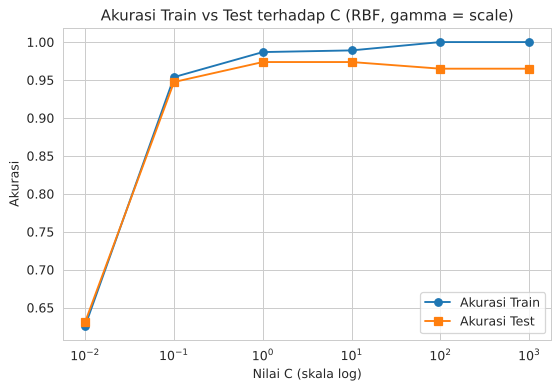

In [20]:
# Plot grafik akurasi training vs testing terhadap nilai C (gunakan sumbu x logaritmik) dalam satu chart.
# Amati pada nilai C berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).
plt.figure(figsize=(7, 4.5))
plt.plot(df_C['C'], df_C['acc_train'], marker='o', label='Akurasi Train')
plt.plot(df_C['C'], df_C['acc_test'], marker='s', label='Akurasi Test')
plt.xscale('log')
plt.xlabel('Nilai C (skala log)')
plt.ylabel('Akurasi')
plt.title('Akurasi Train vs Test terhadap C (RBF, gamma = scale)')
plt.legend()
plt.show()

# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model kernel Linear dan RBF.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
# Kelas positif = Malignant (1)
def hitung_metrik(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred)
    }

tabel_metrik = pd.DataFrame({
    'SVM Linear': hitung_metrik(y_test, y_pred_linear),
    'SVM RBF': hitung_metrik(y_test, y_pred_rbf)
}).T
display(tabel_metrik.round(4))

print("Classification report - Linear")
print(classification_report(y_test, y_pred_linear, target_names=['Benign', 'Malignant']))
print("Classification report - RBF")
print(classification_report(y_test, y_pred_rbf, target_names=['Benign', 'Malignant']))

Classification report - Linear
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114

Classification report - RBF
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



,Accuracy,Precision,Recall,F1-Score
SVM Linear,0.9649,1.0,0.9048,0.950
SVM RBF,0.9737,1.0,0.9286,0.963


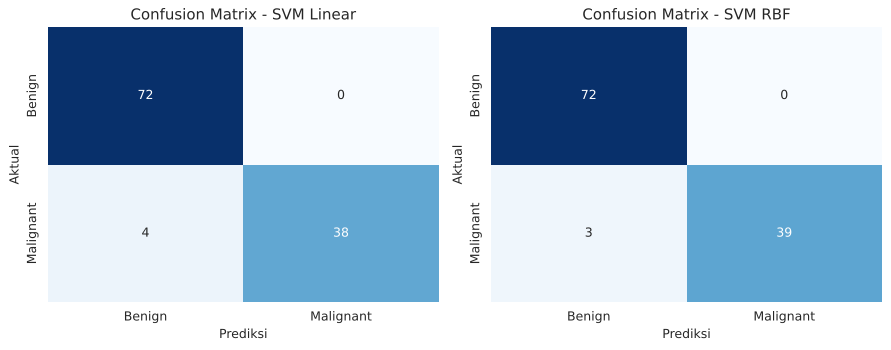

In [22]:
# Tampilkan Confusion Matrix untuk model kernel Linear dan RBF dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, judul in zip(axes, [y_pred_linear, y_pred_rbf], ['SVM Linear', 'SVM RBF']):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    ax.set_title('Confusion Matrix - ' + judul)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
plt.tight_layout()
plt.show()

In [23]:
# Tampilkan jumlah support vectors dari model dengan performa terbaik (atribut model.support_vectors_ atau model.n_support_).
# Bandingkan jumlah support vectors antara model Linear dan RBF.
f1_lin = f1_score(y_test, y_pred_linear)
f1_rbf = f1_score(y_test, y_pred_rbf)
if f1_rbf >= f1_lin:
    model_terbaik, nama_terbaik = svm_rbf, 'RBF'
else:
    model_terbaik, nama_terbaik = svm_linear, 'Linear'
print("Model terbaik berdasarkan F1-Score pada test set:", nama_terbaik)
print()

for nama, m in [('Linear', svm_linear), ('RBF', svm_rbf)]:
    print(f"{nama:7s} | SV per kelas [B, M] = {m.n_support_} | total SV = {m.n_support_.sum()} "
          f"({m.n_support_.sum() / len(X_train_scaled) * 100:.1f}% dari data train)")
print()
print("Bentuk support_vectors_ model terbaik:", model_terbaik.support_vectors_.shape)

Model terbaik berdasarkan F1-Score pada test set: RBF

Linear  | SV per kelas [B, M] = [19 19] | total SV = 38 (8.4% dari data train)
RBF     | SV per kelas [B, M] = [50 57] | total SV = 107 (23.5% dari data train)

Bentuk support_vectors_ model terbaik: (107, 30)


Variance yang dijelaskan 2 PC: [0.446 0.185] | total: 0.631


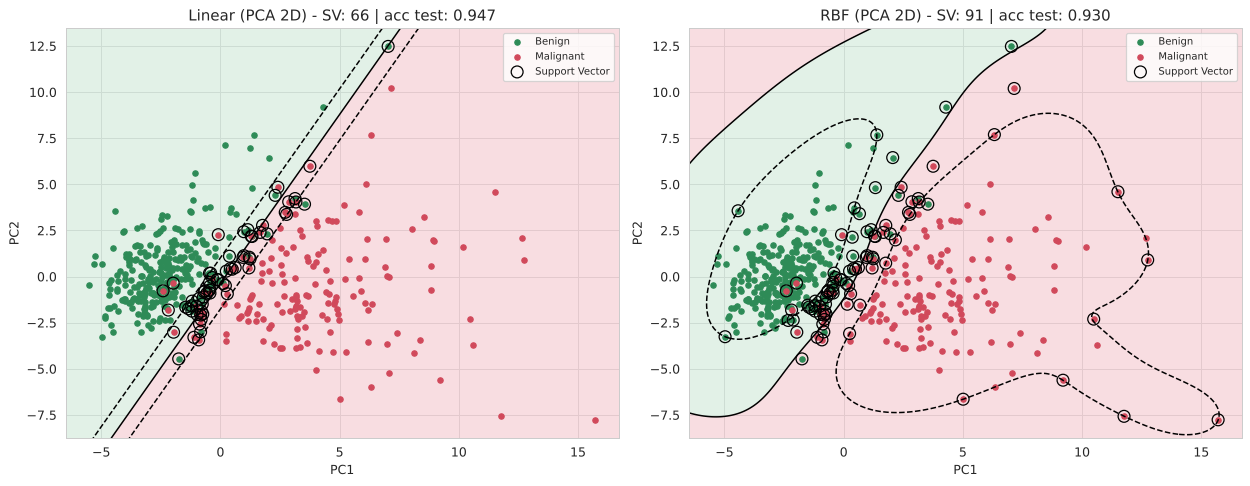

In [24]:
# Jika memungkinkan, pilih dua fitur (atau reduksi dimensi dengan PCA ke 2D) lalu visualisasikan decision boundary
# beserta margin dan support vectors dari model terbaik.

# Reduksi ke 2D dengan PCA (fit di train saja). Model 2D ini dilatih ulang,
# jadi bukan model 30 fitur yang sama, tapi cukup untuk menggambarkan bentuk boundary-nya.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)
print("Variance yang dijelaskan 2 PC:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

def plot_boundary(model, X, y, ax, judul):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-100, 0, 100], colors=['#CFE8D8', '#F4C7CE'], alpha=0.6)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors='k', linestyles=['--', '-', '--'], linewidths=1.2)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c='#2E8B57', s=18, label='Benign')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c='#D1495B', s=18, label='Malignant')
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=90, facecolors='none', edgecolors='k', linewidths=1, label='Support Vector')
    ax.set_title(judul)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(loc='upper right', fontsize=8)

svm_lin_2d = SVC(kernel='linear', C=1.0).fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X_train_2d, y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_boundary(svm_lin_2d, X_train_2d, y_train.values, axes[0],
              f"Linear (PCA 2D) - SV: {svm_lin_2d.n_support_.sum()} | acc test: {svm_lin_2d.score(X_test_2d, y_test):.3f}")
plot_boundary(svm_rbf_2d, X_train_2d, y_train.values, axes[1],
              f"RBF (PCA 2D) - SV: {svm_rbf_2d.n_support_.sum()} | acc test: {svm_rbf_2d.score(X_test_2d, y_test):.3f}")
plt.tight_layout()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa SVM dengan kernel Linear vs RBF. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian, dikaitkan dengan bentuk sebaran data pada EDA?
- Jelaskan temuan dari eksperimen regularisasi (nilai `C`). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Bandingkan jumlah support vectors antara model Linear dan RBF. Apa hubungan jumlah support vectors dengan kompleksitas batas keputusan yang terbentuk?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

## Analisis

### 1. Kernel Linear vs RBF

| Model | Accuracy | Precision | Recall | F1-Score | Support Vector |
|---|---|---|---|---|---|
| SVM Linear (C=1) | 0.9649 | 1.0000 | 0.9048 | 0.9500 | 38 |
| SVM RBF (C=1, gamma=scale) | 0.9737 | 1.0000 | 0.9286 | 0.9630 | 107 |

Hasil kedua model **sangat dekat** dan menurut saya perbedaannya tidak signifikan. Selisih akurasinya 0.88%, atau tepat **1 sampel** dari 114 data test (Linear salah 4 sampel, RBF salah 3 sampel). Test set sekecil ini membuat selisih 1 sampel bisa saja hanya kebetulan hasil pembagian data. RBF memang sedikit unggul di recall dan F1, tapi saya tidak bisa menyimpulkan RBF jelas lebih baik dari satu kali split saja.

Kaitannya dengan EDA: pairplot (misalnya `radius_mean` vs `concave points_mean`) memperlihatkan dua kelas yang hampir bisa dipisah dengan garis lurus, dengan overlap hanya di sedikit titik perbatasan. Karena data sudah cukup linear separable, kernel RBF yang bisa membuat boundary non-linear tidak punya banyak ruang untuk memperbaiki hasil Linear. Data ini juga punya 30 fitur, dan di ruang berdimensi tinggi data lebih mudah dipisahkan oleh hyperplane lurus.

Untuk kedua model **precision = 1.0** (tidak ada Benign yang salah dikira Malignant) dan semua kesalahan berupa *False Negative* (Malignant yang diprediksi Benign: 4 untuk Linear, 3 untuk RBF). Pada kasus diagnosis kanker, ini jenis kesalahan yang paling berbahaya, jadi recall kelas Malignant lebih penting daripada akurasi saja.

### 2. Eksperimen regularisasi (nilai C)

Eksperimen memakai kernel RBF dengan `gamma='scale'` (nilainya 0.033) yang dibuat tetap supaya yang diamati hanya pengaruh C.

| C | Acc Train | Acc Test | Selisih (train-test) | Jumlah SV |
|---|---|---|---|---|
| 0.01 | 0.6264 | 0.6316 | -0.005 | 341 |
| 0.1 | 0.9538 | 0.9474 | 0.007 | 202 |
| 1 | 0.9868 | 0.9737 | 0.013 | 107 |
| 10 | 0.9890 | 0.9737 | 0.015 | 82 |
| 100 | 1.0000 | 0.9649 | 0.035 | 70 |
| 1000 | 1.0000 | 0.9649 | 0.035 | 70 |

- **Underfitting** terjadi pada `C = 0.01`. Akurasi train dan test sama-sama rendah (sekitar 0.63), hampir sama dengan proporsi kelas mayoritas (62.7%), artinya model hampir hanya menebak Benign. Regularisasi terlalu kuat sehingga margin terlalu lebar dan hampir semua titik menjadi support vector (341 dari 455).
- Hasil terbaik ada di sekitar `C = 1` sampai `C = 10`: akurasi test tertinggi (0.9737) dan selisih train-test masih kecil (1-1.5%).
- **Gejala overfitting** mulai terlihat pada **`C = 100`**. Akurasi train naik menjadi 1.0, sedangkan akurasi test turun dari 0.9737 menjadi 0.9649, sehingga selisihnya naik menjadi 3.5%. Di grafik, ciri-cirinya garis train terus naik sampai menempel di 1.0, sementara garis test mendatar lalu turun sedikit, sehingga jarak kedua garis melebar. Pada `C = 1000` hasilnya sama persis dengan `C = 100`, karena semua data train sudah terklasifikasi benar.
- Catatan jujur: penurunan test dari 0.9737 ke 0.9649 hanya beda 1 sampel, jadi overfitting di C besar pada dataset ini tergolong **ringan**. Data yang cukup bersih dan terpisah baik membuat model relatif tahan terhadap overfitting.
- Terlihat juga bahwa makin besar C, jumlah support vector makin sedikit (341 menjadi 70), karena margin menyempit dan toleransi terhadap kesalahan klasifikasi makin kecil.

### 3. Jumlah support vector

| Model | SV Benign | SV Malignant | Total | % dari data train |
|---|---|---|---|---|
| Linear | 19 | 19 | 38 | 8.4% |
| RBF | 50 | 57 | 107 | 23.5% |

Model Linear hanya butuh 38 support vector, sedangkan RBF butuh 107 (hampir 3 kali lipat). Support vector adalah titik-titik yang menentukan posisi boundary. Boundary linear berupa satu bidang lurus, sehingga sedikit titik di dekat margin sudah cukup untuk menentukannya. Boundary RBF yang melengkung dan fleksibel perlu ditopang lebih banyak titik. Jadi, semakin banyak support vector, secara umum semakin kompleks batas keputusan yang terbentuk.

Pada visualisasi PCA 2D (2 komponen hanya menjelaskan 63.1% variansi, dan modelnya dilatih ulang di 2 dimensi, jadi ini hanya gambaran kasar), boundary Linear berupa garis lurus (66 SV, akurasi test 0.947), sedangkan boundary RBF melengkung dan tidak beraturan (91 SV, akurasi test 0.930). Di 2D RBF justru tidak lebih baik dari Linear, yang sejalan dengan dugaan bahwa data memang cukup linear sehingga fleksibilitas ekstra RBF tidak banyak membantu.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba kernel Polynomial, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan

1. Dataset (Breast Cancer Wisconsin, 569 data, 30 fitur) cukup bersih dan kelasnya sedikit imbalanced (62.7% Benign : 37.3% Malignant). Setelah kolom kosong `Unnamed: 32` dan kolom `id` dibuang, tidak ada missing value tersisa.
2. Rentang nilai antar fitur sangat timpang (misalnya `area` ribuan vs `smoothness` sekitar 0.1), sehingga feature scaling dengan `StandardScaler` diperlukan untuk SVM. Scaler di-fit hanya pada data train agar tidak terjadi data leakage.
3. **Linear vs RBF:** keduanya sama-sama bagus. Linear mencapai akurasi 96.5% dan RBF 97.4%, hanya beda 1 sampel di test set. Perbedaan ini tidak cukup untuk menyatakan RBF jelas lebih baik, karena dari EDA data memang hampir terpisah secara linear. RBF memerlukan lebih banyak support vector (107 vs 38), jadi modelnya lebih kompleks tanpa keuntungan yang berarti. Kernel Linear sudah cukup dan lebih sederhana untuk dataset ini.
4. **Pengaruh C:** C terlalu kecil (0.01) menyebabkan underfitting (akurasi sekitar 63%), C sedang (1-10) memberi hasil terbaik (test 97.4%), dan C besar (>= 100) mulai menunjukkan gejala overfitting ringan (train 100%, test turun menjadi 96.5%).
5. Semua kesalahan prediksi kedua model berupa False Negative (tidak ada False Positive). Ini perlu diwaspadai karena kasus Malignant yang terlewat lebih berbahaya.

## Saran

- Pemilihan `C` dan `gamma` sebaiknya dilakukan dengan **GridSearchCV / cross-validation** pada data train, lalu dipakai **Pipeline** (scaler + SVC) agar scaling dilakukan di dalam tiap fold. Pada tugas ini `gamma` hanya dibuat tetap (`'scale'`), jadi pengaruhnya belum dieksplorasi.
- Test set hanya 114 data, sehingga hasil satu kali split kurang stabil. Sebaiknya dievaluasi dengan k-fold cross-validation atau beberapa `random_state`.
- Karena recall Malignant lebih penting, bisa dicoba `class_weight='balanced'` atau menggeser threshold keputusan agar False Negative berkurang.
- Bisa dicoba kernel lain (Polynomial), seleksi fitur atau PCA untuk mengurangi fitur yang redundan, serta perbandingan dengan model lain seperti Logistic Regression, Random Forest, atau KNN.